# CSC 4110 – Machine Learning

## Group G9 – Staff Attrition

### Task 3.2: Polynomial and Regularised Regression

**Owner:** Jack Otuko

**Registration Number:** COM/0059/23

**Dataset:** IBM HR Analytics Employee Attrition

**Objective:** Compare polynomial regression, Ridge regression and Lasso regression to identify a suitable model for predicting monthly employee income.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import data_table
data_table.disable_dataframe_formatter()

# Load the cleaned HR dataset
file_path = "/content/drive/MyDrive/CSC4110_G09/data/clean_hr.csv"

df_clean = pd.read_csv(file_path)

# Display dataset information
print("Dataset shape:", df_clean.shape)
display(df_clean.head())

Dataset shape: (1470, 51)


,Age,Attrition,BusinessTravel,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,Gender_Female,Gender_Male,years_per_company,age_band
0,41,1,1,1102,1,2,2,94,3,2,...,0,1,0,0,0,1,1,0,0.888889,40-49
1,49,0,2,279,8,1,3,61,2,2,...,1,0,0,0,1,0,0,1,5.000000,40-49
2,37,1,1,1373,2,2,4,92,2,1,...,0,0,0,0,0,1,0,1,1.000000,30-39
3,33,0,2,1392,3,4,4,56,3,1,...,1,0,0,0,1,0,1,0,4.000000,30-39
4,27,0,1,591,2,1,1,40,3,1,...,0,0,0,0,1,0,0,1,0.600000,18-29


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select the target variable
target_column = "MonthlyIncome"

# Separate input features and target
excluded_columns = ["MonthlyIncome", "Attrition", "JobLevel", "age_band"]

X = df_clean.drop(columns=excluded_columns)
y = df_clean[target_column]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=df_clean["Attrition"]
)

# Standardise the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Target variable:", y.name)

Training data: (1176, 47)
Testing data: (294, 47)
Target variable: MonthlyIncome


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Select the feature
X_poly_train = X_train[["TotalWorkingYears"]]
X_poly_test = X_test[["TotalWorkingYears"]]

# Store results
poly_results = []

# Test polynomial degrees 1, 2 and 3
for degree in [1, 2, 3]:

    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    # Train the model
    model.fit(X_poly_train, y_train)

    # Make predictions
    train_predictions = model.predict(X_poly_train)
    test_predictions = model.predict(X_poly_test)

    # Calculate RMSE
    train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

    # Save results
    poly_results.append({
        "Degree": degree,
        "Train_RMSE": train_rmse,
        "Test_RMSE": test_rmse
    })

# Display results
poly_results = pd.DataFrame(poly_results)
print(poly_results)

   Degree   Train_RMSE    Test_RMSE
0       1  2940.705097  3163.781376
1       2  2936.705530  3162.378087
2       3  2911.796815  3088.295884


In [ ]:
from sklearn.linear_model import Ridge, Lasso

alphas = [0.01, 0.1, 1, 10]

regularisation_results = []

for alpha in alphas:

    # Ridge Regression
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)

    ridge_predictions = ridge.predict(X_test_scaled)

    ridge_rmse = np.sqrt(
        mean_squared_error(y_test, ridge_predictions)
    )

    ridge_zeros = np.sum(np.abs(ridge.coef_) < 1e-8)

    # Lasso Regression
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_scaled, y_train)

    lasso_predictions = lasso.predict(X_test_scaled)

    lasso_rmse = np.sqrt(
        mean_squared_error(y_test, lasso_predictions)
    )

    lasso_zeros = np.sum(np.abs(lasso.coef_) < 1e-8)

    # Store results
    regularisation_results.append({
        "Alpha": alpha,
        "Ridge_RMSE": ridge_rmse,
        "Ridge_Zero_Coefficients": ridge_zeros,
        "Lasso_RMSE": lasso_rmse,
        "Lasso_Zero_Coefficients": lasso_zeros
    })

regularisation_results = pd.DataFrame(regularisation_results)

print(regularisation_results)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.632e+07, tolerance: 2.545e+06
  model = cd_fast.enet_coordinate_descent(


   Alpha   Ridge_RMSE  Ridge_Zero_Coefficients   Lasso_RMSE  \
0   0.01  1693.763034                        0  1693.758425   
1   0.10  1693.798902                        0  1693.749304   
2   1.00  1694.159697                        0  1693.692366   
3  10.00  1697.973151                        0  1691.938295   

   Lasso_Zero_Coefficients  
0                        3  
1                        5  
2                        5  
3                       15  


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error

results_reg = []

# Multiple Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

linear_predictions = linear_model.predict(X_test_scaled)

results_reg.append({
    "Model": "Multiple Linear Regression",
    "Test_RMSE": np.sqrt(mean_squared_error(y_test, linear_predictions))
})

# Polynomial Regression
for degree in [1, 2, 3]:

    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train[["TotalWorkingYears"]], y_train)

    predictions = model.predict(X_test[["TotalWorkingYears"]])

    results_reg.append({
        "Model": f"Polynomial Degree {degree}",
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

# Ridge and Lasso Regression
for alpha in [0.01, 0.1, 1, 10]:

    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)

    ridge_predictions = ridge.predict(X_test_scaled)

    results_reg.append({
        "Model": f"Ridge alpha={alpha}",
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, ridge_predictions))
    })

    lasso = Lasso(alpha=alpha, max_iter=50000)
    lasso.fit(X_train_scaled, y_train)

    lasso_predictions = lasso.predict(X_test_scaled)

    results_reg.append({
        "Model": f"Lasso alpha={alpha}",
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, lasso_predictions))
    })

# Display comparison
results_reg = pd.DataFrame(results_reg)
results_reg = results_reg.sort_values("Test_RMSE")

print(results_reg)

                         Model    Test_RMSE
11              Lasso alpha=10  1691.938295
9                Lasso alpha=1  1693.692366
7              Lasso alpha=0.1  1693.749304
5             Lasso alpha=0.01  1693.758041
0   Multiple Linear Regression  1693.759051
4             Ridge alpha=0.01  1693.763034
6              Ridge alpha=0.1  1693.798902
8                Ridge alpha=1  1694.159697
10              Ridge alpha=10  1697.973151
3          Polynomial Degree 3  3088.295884
2          Polynomial Degree 2  3162.378087
1          Polynomial Degree 1  3163.781376


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# Create features including JobLevel
X_with_joblevel = df_clean.drop(
    columns=["MonthlyIncome", "Attrition", "age_band"]
)

# Use the same training and testing employees
X_train_job = X_with_joblevel.loc[X_train.index]
X_test_job = X_with_joblevel.loc[X_test.index]

# Scale the new features
scaler_job = StandardScaler()

X_train_job_scaled = scaler_job.fit_transform(X_train_job)
X_test_job_scaled = scaler_job.transform(X_test_job)

# Train the original model without JobLevel
model_without_joblevel = LinearRegression()
model_without_joblevel.fit(X_train_scaled, y_train)

pred_without = model_without_joblevel.predict(X_test_scaled)
r2_without = r2_score(y_test, pred_without)

# Train the new model with JobLevel
model_with_joblevel = LinearRegression()
model_with_joblevel.fit(X_train_job_scaled, y_train)

pred_with = model_with_joblevel.predict(X_test_job_scaled)
r2_with = r2_score(y_test, pred_with)

# Calculate the change in R-squared
r2_change = r2_with - r2_without

print("R² without JobLevel:", round(r2_without, 4))
print("R² with JobLevel:", round(r2_with, 4))
print("Change in R²:", round(r2_change, 4))
print("Percentage point change:", round(r2_change * 100, 2))

R² without JobLevel: 0.8813
R² with JobLevel: 0.9541
Change in R²: 0.0729
Percentage point change: 7.29


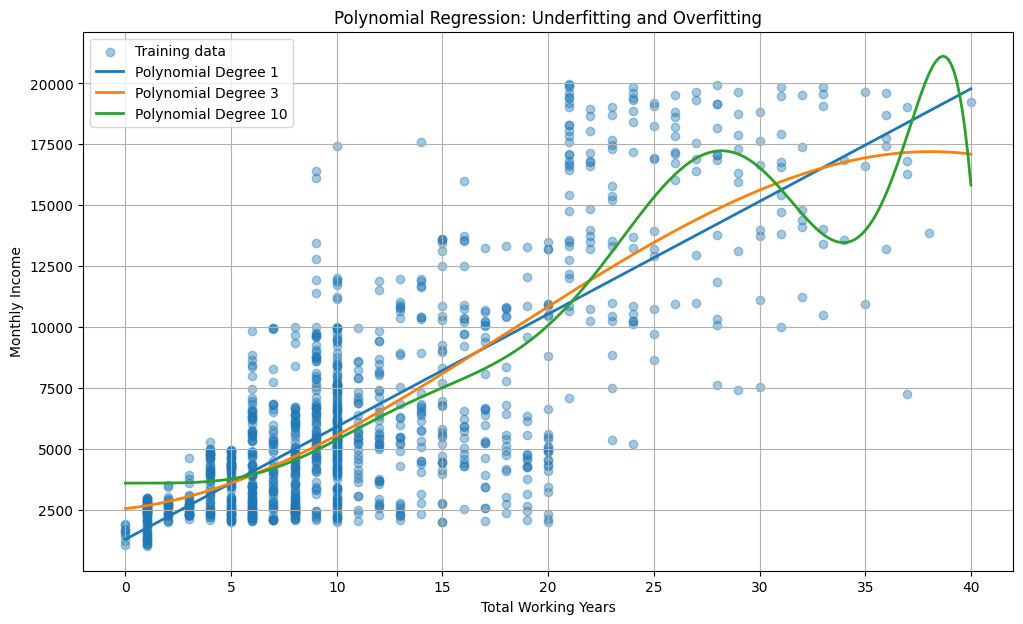

Graph saved successfully at: /content/drive/MyDrive/CSC4110_G09/outputs/under_over_fit.png


In [ ]:
# Task 3.2: Plot polynomial degrees 1, 3 and 10
# to demonstrate underfitting and overfitting

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Create the outputs folder
output_path = "/content/drive/MyDrive/CSC4110_G09/outputs"
os.makedirs(output_path, exist_ok=True)

# Select TotalWorkingYears
X_train_poly = X_train[["TotalWorkingYears"]]

# Generate smooth x-values for plotting
x_curve = pd.DataFrame({
    "TotalWorkingYears": np.linspace(
        X_train_poly["TotalWorkingYears"].min(),
        X_train_poly["TotalWorkingYears"].max(),
        300
    )
})

# Create the plot
plt.figure(figsize=(12, 7))

# Plot the training data
plt.scatter(
    X_train_poly["TotalWorkingYears"],
    y_train,
    alpha=0.4,
    label="Training data"
)

# Fit and plot polynomial degrees 1, 3 and 10
for degree in [1, 3, 10]:

    # Create polynomial regression pipeline
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    # Train the model
    model.fit(X_train_poly, y_train)

    # Predict values for the smooth curve
    predictions = model.predict(x_curve)

    # Plot the fitted curve
    plt.plot(
        x_curve["TotalWorkingYears"],
        predictions,
        label=f"Polynomial Degree {degree}",
        linewidth=2
    )

# Add chart labels
plt.xlabel("Total Working Years")
plt.ylabel("Monthly Income")
plt.title("Polynomial Regression: Underfitting and Overfitting")
plt.legend()
plt.grid(True)

# Save the graph
plt.savefig(
    os.path.join(output_path, "under_over_fit.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully at:", output_path + "/under_over_fit.png")

In [ ]:
# Task 3.2: Ridge and Lasso regularisation

from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# Alpha values required by the assignment
alphas = [0.01, 0.1, 1, 10]

ridge_records = []
lasso_records = []

# Fit Ridge and Lasso models for each alpha
for alpha in alphas:

    # Ridge regression
    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(X_train_scaled, y_train)

    ridge_predictions = ridge_model.predict(X_test_scaled)
    ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))

    ridge_records.append({
        "Alpha": alpha,
        "Test_RMSE": ridge_rmse
    })

    # Lasso regression
    lasso_model = Lasso(alpha=alpha, max_iter=100000)
    lasso_model.fit(X_train_scaled, y_train)

    lasso_predictions = lasso_model.predict(X_test_scaled)
    lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))

    # Count coefficients that are exactly zero
    zero_count = np.sum(lasso_model.coef_ == 0)

    lasso_records.append({
        "Alpha": alpha,
        "Test_RMSE": lasso_rmse,
        "Zero_Coefficients": zero_count
    })

    # Check whether the three required features survive
    if alpha == 10:
        feature_status = pd.DataFrame({
            "Feature": X_train.columns,
            "Coefficient": lasso_model.coef_
        })

        print("Feature survival at alpha = 10:")
        for feature in ["DailyRate", "HourlyRate", "MonthlyRate"]:
            coefficient = feature_status.loc[
                feature_status["Feature"] == feature,
                "Coefficient"
            ].iloc[0]

            status = "Survives" if coefficient != 0 else "Removed"
            print(f"{feature}: {status} (coefficient = {coefficient})")

# Create the required result DataFrames
ridge_results = pd.DataFrame(ridge_records)
lasso_results = pd.DataFrame(lasso_records)

print("\nRIDGE RESULTS")
print(ridge_results)

print("\nLASSO RESULTS")
print(lasso_results)

Feature survival at alpha = 10:
DailyRate: Survives (coefficient = 58.46976289788762)
HourlyRate: Removed (coefficient = -0.0)
MonthlyRate: Survives (coefficient = -47.98193834236944)

RIDGE RESULTS
   Alpha    Test_RMSE
0   0.01  1693.763034
1   0.10  1693.798902
2   1.00  1694.159697
3  10.00  1697.973151

LASSO RESULTS
   Alpha    Test_RMSE  Zero_Coefficients
0   0.01  1693.758041                  5
1   0.10  1693.749304                  5
2   1.00  1693.692366                  4
3  10.00  1691.938295                 15


In [ ]:
# Task 3.2: Compare the four best regression models

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Store comparison results
comparison = []

# Function to calculate test metrics
def evaluate_model(model_name, model, X_train_data, X_test_data):
    model.fit(X_train_data, y_train)
    predictions = model.predict(X_test_data)

    comparison.append({
        "Model": model_name,
        "Test_MAE": mean_absolute_error(y_test, predictions),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test_R2": r2_score(y_test, predictions)
    })

# 1. Multiple Linear Regression
linear_model = LinearRegression()
evaluate_model(
    "Multiple Linear Regression",
    linear_model,
    X_train_scaled,
    X_test_scaled
)

# 2. Best Polynomial Regression (degree 3)
poly_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

evaluate_model(
    "Polynomial Regression (Degree 3)",
    poly_model,
    X_train[["TotalWorkingYears"]],
    X_test[["TotalWorkingYears"]]
)

# 3. Best Ridge Regression (alpha = 0.01)
ridge_model = Ridge(alpha=0.01)
evaluate_model(
    "Ridge Regression (alpha=0.01)",
    ridge_model,
    X_train_scaled,
    X_test_scaled
)

# 4. Best Lasso Regression (alpha = 10)
lasso_model = Lasso(alpha=10, max_iter=100000)
evaluate_model(
    "Lasso Regression (alpha=10)",
    lasso_model,
    X_train_scaled,
    X_test_scaled
)

# Create the required comparison DataFrame
results_reg = pd.DataFrame(comparison)

print("REGRESSION MODEL COMPARISON")
print(results_reg)

REGRESSION MODEL COMPARISON
                              Model     Test_MAE    Test_RMSE   Test_R2
0        Multiple Linear Regression  1325.386980  1693.759051  0.881255
1  Polynomial Regression (Degree 3)  2304.747737  3088.295884  0.605224
2     Ridge Regression (alpha=0.01)  1325.391681  1693.763034  0.881254
3       Lasso Regression (alpha=10)  1324.235606  1691.938295  0.881510


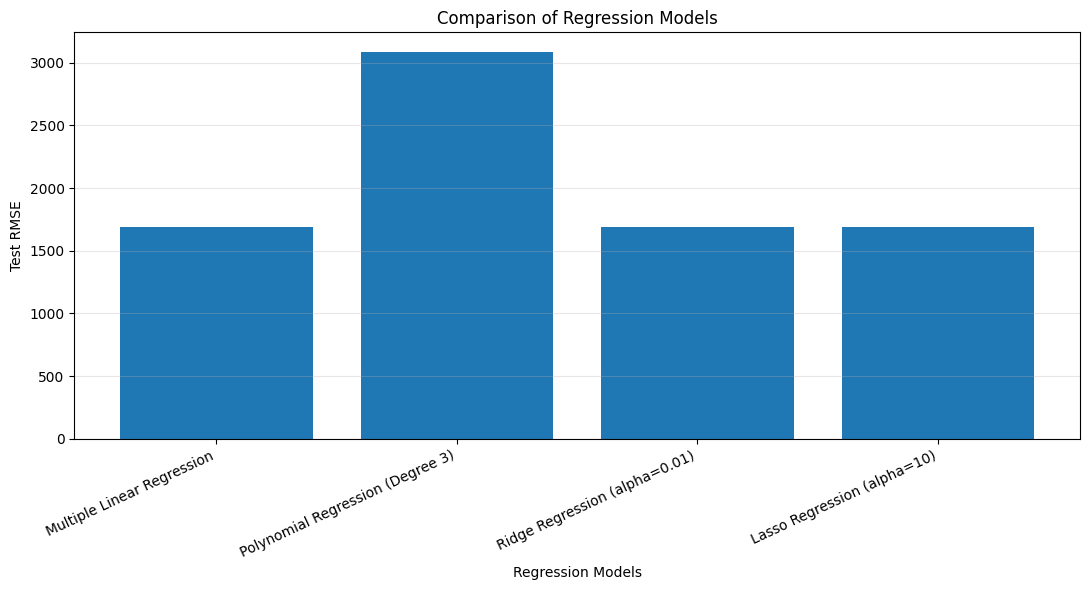

Graph saved successfully at: /content/drive/MyDrive/CSC4110_G09/outputs/regression_comparison.png


In [ ]:
# Task 3.2: Plot and save regression model comparison

import os
import matplotlib.pyplot as plt

# Create the outputs folder if it does not exist
output_path = "/content/drive/MyDrive/CSC4110_G09/outputs"
os.makedirs(output_path, exist_ok=True)

# Plot test RMSE for each regression model
plt.figure(figsize=(11, 6))

plt.bar(
    results_reg["Model"],
    results_reg["Test_RMSE"]
)

plt.xlabel("Regression Models")
plt.ylabel("Test RMSE")
plt.title("Comparison of Regression Models")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save the comparison graph
chart_path = os.path.join(
    output_path,
    "regression_comparison.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved successfully at:", chart_path)

In [ ]:
# Task 3.2: Measure the effect of adding JobLevel

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# Prepare features including JobLevel
X_with_joblevel = df_clean.drop(
    columns=["MonthlyIncome", "Attrition", "age_band"]
)

# Use the same training and testing rows
X_train_job = X_with_joblevel.loc[X_train.index]
X_test_job = X_with_joblevel.loc[X_test.index]

# Scale the features
scaler_job = StandardScaler()

X_train_job_scaled = scaler_job.fit_transform(X_train_job)
X_test_job_scaled = scaler_job.transform(X_test_job)

# Model without JobLevel
model_without_joblevel = LinearRegression()
model_without_joblevel.fit(X_train_scaled, y_train)

pred_without = model_without_joblevel.predict(X_test_scaled)
r2_without = r2_score(y_test, pred_without)

# Model with JobLevel
model_with_joblevel = LinearRegression()
model_with_joblevel.fit(X_train_job_scaled, y_train)

pred_with = model_with_joblevel.predict(X_test_job_scaled)
r2_with = r2_score(y_test, pred_with)

# Calculate the improvement
r2_change = r2_with - r2_without

print("R² WITHOUT JobLevel:", round(r2_without, 4))
print("R² WITH JobLevel:", round(r2_with, 4))
print("R² improvement:", round(r2_change, 4))
print("Improvement in percentage points:", round(r2_change * 100, 2))

R² WITHOUT JobLevel: 0.8813
R² WITH JobLevel: 0.9541
R² improvement: 0.0729
Improvement in percentage points: 7.29


In [ ]:
# Task 3.2: Check overfitting and identify important features

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# Define models
models = {
    "Multiple Linear Regression": LinearRegression(),
    "Polynomial Degree 3": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        LinearRegression()
    ),
    "Ridge alpha=0.01": Ridge(alpha=0.01),
    "Lasso alpha=10": Lasso(alpha=10, max_iter=100000)
}

# Match each model with its training and testing features
model_data = {
    "Multiple Linear Regression": (X_train_scaled, X_test_scaled),
    "Polynomial Degree 3": (
        X_train[["TotalWorkingYears"]],
        X_test[["TotalWorkingYears"]]
    ),
    "Ridge alpha=0.01": (X_train_scaled, X_test_scaled),
    "Lasso alpha=10": (X_train_scaled, X_test_scaled)
}

# Calculate training and testing RMSE
overfit_records = []

for name, model in models.items():
    Xtr, Xte = model_data[name]

    model.fit(Xtr, y_train)

    train_predictions = model.predict(Xtr)
    test_predictions = model.predict(Xte)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

    overfit_records.append({
        "Model": name,
        "Training_RMSE": train_rmse,
        "Test_RMSE": test_rmse
    })

overfit_results = pd.DataFrame(overfit_records)

print("TRAINING VS TEST RMSE")
print(overfit_results)

# Identify the most influential features using standardised coefficients
importance_model = LinearRegression()
importance_model.fit(X_train_scaled, y_train)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": importance_model.coef_,
    "Absolute_Importance": np.abs(importance_model.coef_)
})

feature_importance = feature_importance.sort_values(
    by="Absolute_Importance",
    ascending=False
)

print("TOP 10 FEATURES BY ABSOLUTE STANDARDISED COEFFICIENT")
print(feature_importance.head(10))

TRAINING VS TEST RMSE
                        Model  Training_RMSE    Test_RMSE
0  Multiple Linear Regression    1618.267021  1693.759051
1         Polynomial Degree 3    2911.796815  3088.295884
2            Ridge alpha=0.01    1618.267022  1693.763034
3              Lasso alpha=10    1620.385877  1691.938295
TOP 10 FEATURES BY ABSOLUTE STANDARDISED COEFFICIENT
                          Feature  Coefficient  Absolute_Importance
35                JobRole_Manager  1941.456026          1941.456026
16              TotalWorkingYears  1616.181105          1616.181105
37      JobRole_Research Director  1589.219904          1589.219904
38     JobRole_Research Scientist -1076.192615          1076.192615
34  JobRole_Laboratory Technician -1063.087697          1063.087697
40   JobRole_Sales Representative  -542.568044           542.568044
33        JobRole_Human Resources  -341.551922           341.551922
39        JobRole_Sales Executive   250.070084           250.070084
22           YearsWithC

### Task 3.2: Conclusion

**1. Best-performing model**

Lasso Regression with alpha = 10 performed best on the test set. It achieved a test RMSE of 1691.94, MAE of 1324.24 and R² of 0.8815. It performed slightly better than Multiple Linear Regression and Ridge Regression.

**2. Overfitting analysis**

All four models recorded higher test RMSE than training RMSE, indicating a small generalisation gap. Polynomial Regression (Degree 3) had a larger gap than the other three models. The Degree 10 curve also demonstrated visual overfitting, while Degree 1 demonstrated underfitting.

**3. Important features**

The most influential features in the multiple linear regression model included JobRole_Manager, TotalWorkingYears, JobRole_Research Director, JobRole_Research Scientist and JobRole_Laboratory Technician. This suggests that job role and work experience are important predictors of monthly income.

**4. Effect of JobLevel**

Adding JobLevel increased the model's R² from 0.8813 to 0.9541, an improvement of 7.29 percentage points. This indicates that JobLevel provides substantial predictive information about MonthlyIncome. However, this does not establish a causal relationship.

**5. Lasso feature selection**

Lasso Regression reduced the number of active features by setting some coefficients exactly to zero. At alpha = 10, 15 coefficients became zero. DailyRate and MonthlyRate survived, while HourlyRate was removed.

**Conclusion**

Lasso Regression with alpha = 10 was the best-performing model among the four compared models. JobLevel substantially improved the prediction of MonthlyIncome, while Lasso helped simplify the model through feature selection.